# Hifsah CKD — kidney CT image dataset
## 1. Setup

In [1]:
import os, shutil
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = 'dataset'

## 2. Clean junk files (.DS_Store, ._*, Thumbs.db, __MACOSX ...)
Junk is moved to `_junk/` (outside the dataset), not deleted.

In [2]:
JUNK = {'.DS_Store', 'Thumbs.db', 'desktop.ini', '__MACOSX', '.ipynb_checkpoints'}
junk = [os.path.join(dp, n) for dp, ds, fs in os.walk(ROOT) for n in ds + fs if n in JUNK or n.startswith('.')]
print(len(junk), 'junk items found')
junk[:10]

0 junk items found


[]

In [3]:
os.makedirs('_junk', exist_ok=True)
for p in junk: shutil.move(p, os.path.join('_junk', p.replace(os.sep, '__')))
print('moved', len(junk), 'items')

moved 0 items


## 3. Read the dataset

In [4]:
classes = sorted(d for d in os.listdir(ROOT) if os.path.isdir(os.path.join(ROOT, d)))
classes

['Cyst', 'Normal', 'Stone', 'Tumor']

In [5]:
df = pd.DataFrame([(os.path.join(ROOT, c, f), c) for c in classes for f in sorted(os.listdir(os.path.join(ROOT, c)))], columns=['path', 'label'])
df.label.value_counts()

label
Normal    5077
Cyst      3709
Tumor     2283
Stone     1377
Name: count, dtype: int64

In [6]:
df['ext'] = df.path.str.rsplit('.', n=1).str[-1].str.lower()
df.ext.value_counts()

ext
jpg    12446
Name: count, dtype: int64

## 4. Image sizes and colour modes

In [7]:
meta = [(im.size[0], im.size[1], im.mode) for im in map(Image.open, df.path)]
df[['w', 'h', 'mode']] = meta
df['mode'].value_counts()

mode
RGB    12446
Name: count, dtype: int64

In [8]:
df[['w', 'h']].value_counts().head(10)

w     h   
512   512     7709
798   646      240
804   651      179
768   622      177
840   680      171
764   619      160
1236  1001     155
787   636      141
705   569      140
882   714      131
Name: count, dtype: int64

## 5. Sample images

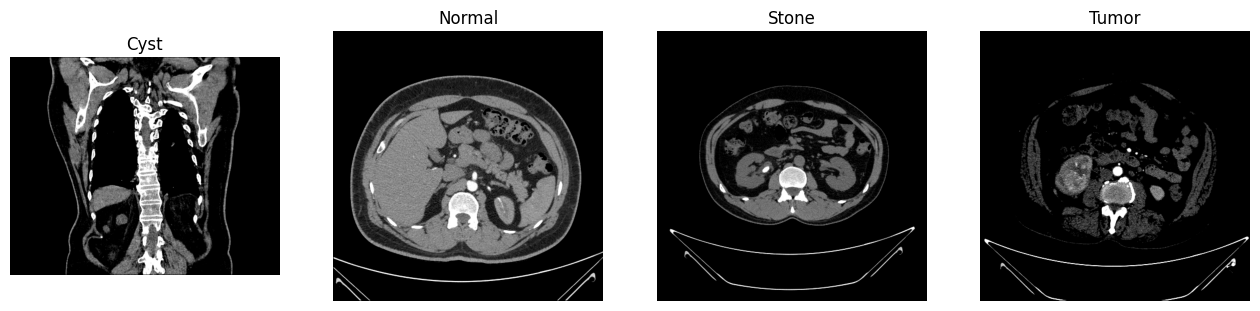

In [9]:
fig, axes = plt.subplots(1, len(classes), figsize=(16, 4))
for ax, c in zip(axes, classes): ax.imshow(Image.open(df[df.label == c].path.iloc[0])); ax.set_title(c); ax.axis('off')

## 6. Understanding the images
### 6.1 Random samples (6 per class)

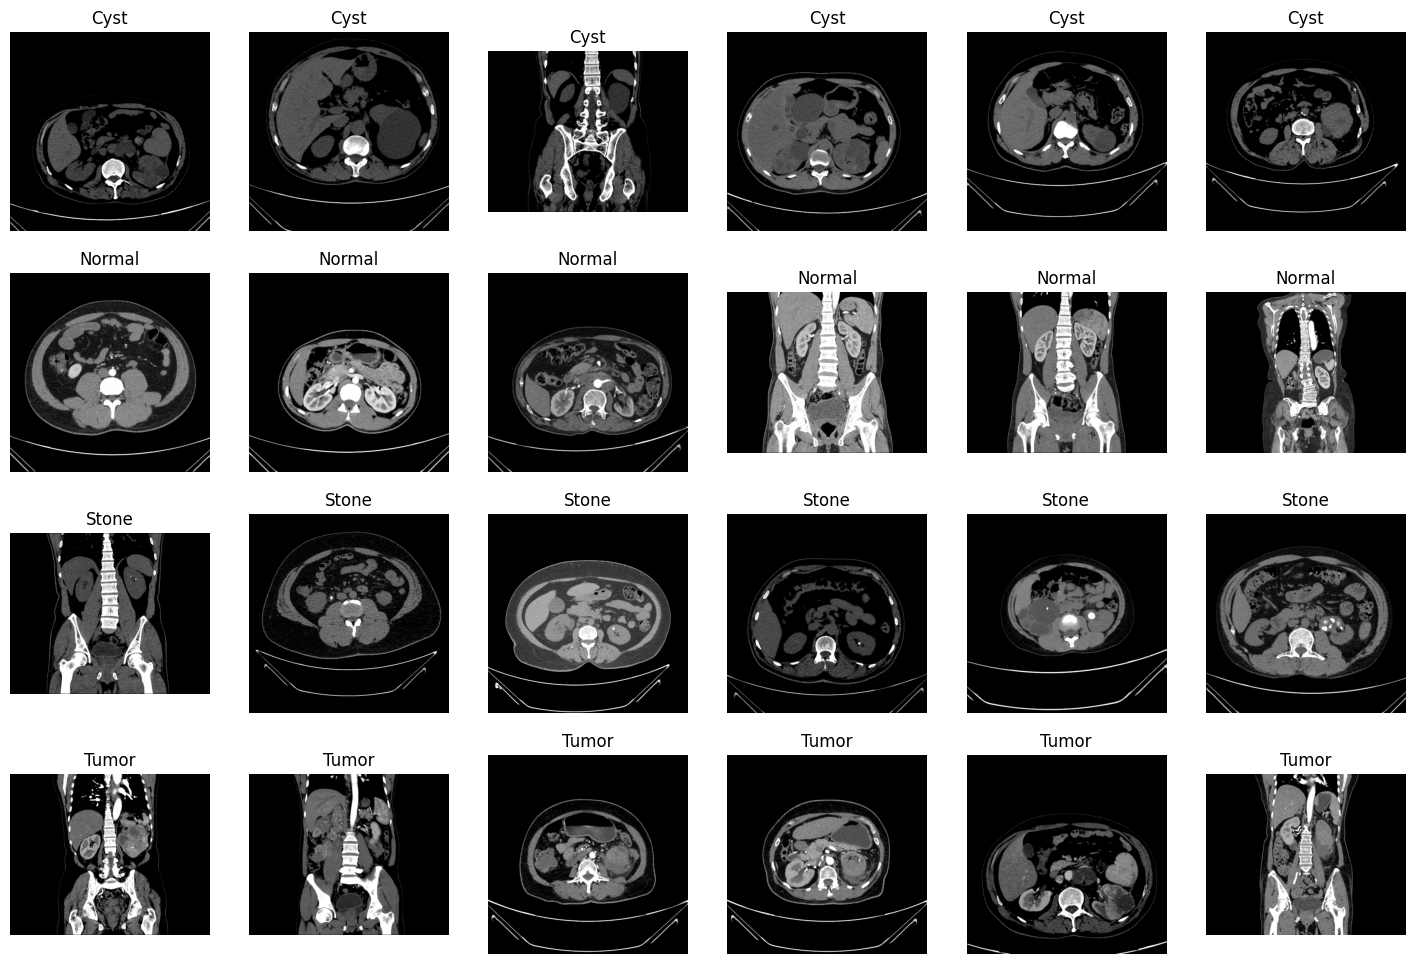

In [10]:
samples = df.groupby('label').sample(6, random_state=1)
fig, axes = plt.subplots(4, 6, figsize=(18, 12))
for ax, p, c in zip(axes.flat, samples.path, samples.label): ax.imshow(Image.open(p)); ax.set_title(c); ax.axis('off')

### 6.2 Pixel values — are the images really colour?

In [11]:
import numpy as np
a = np.array(Image.open(df.path[0])).astype(int)
print('shape:', a.shape, '| min/max:', a.min(), a.max())
print('max difference between R, G, B channels:', np.abs(a[..., 0] - a[..., 1]).max(), np.abs(a[..., 1] - a[..., 2]).max())

shape: (569, 705, 3) | min/max: 0 255
max difference between R, G, B channels: 0 0


### 6.3 Consecutive file numbers — neighbouring CT slices?

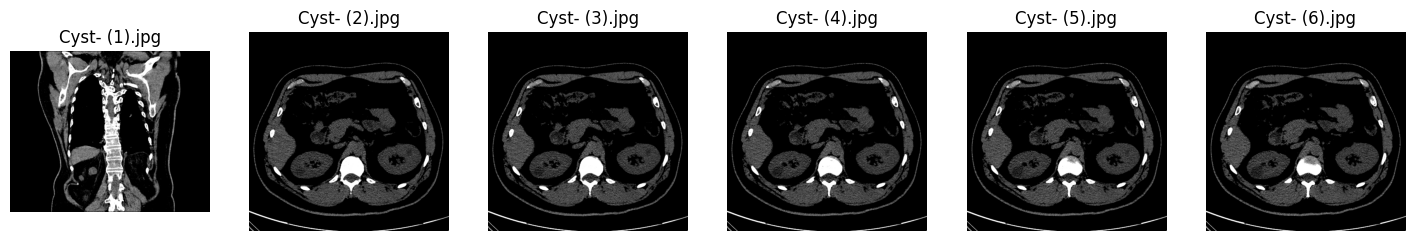

In [12]:
seq = [os.path.join(ROOT, 'Cyst', f'Cyst- ({i}).jpg') for i in range(1, 7)]
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for ax, p in zip(axes, seq): ax.imshow(Image.open(p)); ax.set_title(os.path.basename(p)); ax.axis('off')

### 6.4 Does image size differ by class? (a possible shortcut for the model)

In [13]:
df['is_512'] = (df.w == 512) & (df.h == 512)
pd.crosstab(df.label, df.is_512)

is_512,False,True
label,,
Cyst,1462,2247
Normal,1803,3274
Stone,529,848
Tumor,943,1340


### 6.5 Average brightness per class

In [14]:
df['mean_px'] = [np.array(Image.open(p).convert('L')).mean() for p in df.path]
df.groupby('label').mean_px.describe().round(1)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Cyst,3709.0,26.4,9.4,7.8,18.7,24.4,33.3,51.9
Normal,5077.0,44.7,14.7,15.6,33.1,42.8,56.1,82.4
Stone,1377.0,35.4,13.4,10.3,23.8,35.4,43.5,85.2
Tumor,2283.0,36.3,13.5,13.2,24.9,34.0,45.3,70.5


## 7. More image analytics
Load every image once as a small 64×64 grayscale array (used by all cells below).

In [15]:
small = np.stack([np.array(Image.open(p).convert('L').resize((64, 64))) for p in df.path])
small.shape

(12446, 64, 64)

### 7.1 Mean image per class — any systematic difference in position, framing or brightness?

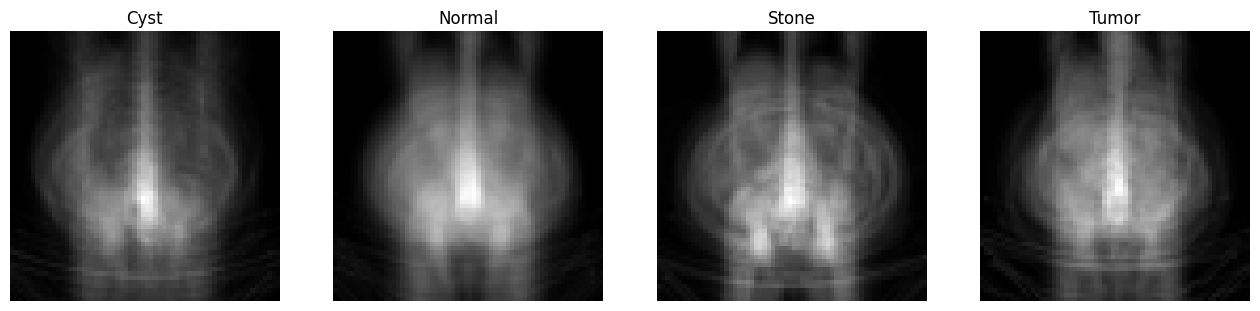

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, classes): ax.imshow(small[df.label == c].mean(0), cmap='gray'); ax.set_title(c); ax.axis('off')

### 7.2 Pixel-intensity histogram per class

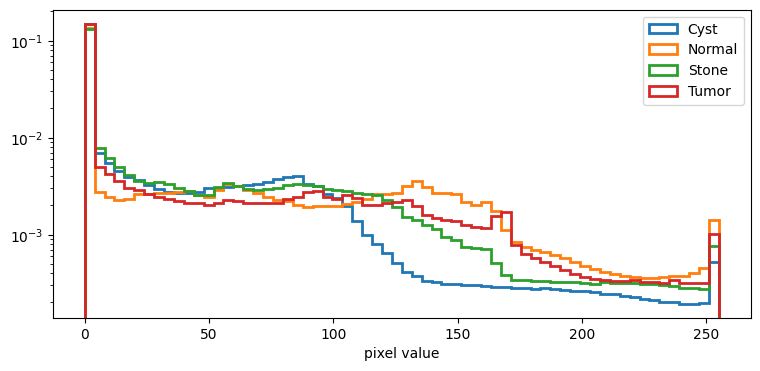

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
for c in classes: ax.hist(small[df.label == c].ravel(), bins=64, density=True, histtype='step', lw=2, label=c)
ax.set_yscale('log'); ax.set_xlabel('pixel value'); ax.legend()

### 7.3 Contrast per image — flag nearly blank / washed-out images

In [18]:
df['std_px'] = small.reshape(len(df), -1).std(1)
print('low-contrast images (std < 20):', (df.std_px < 20).sum())
df.groupby('label').std_px.describe().round(1)

low-contrast images (std < 20): 0


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Cyst,3709.0,43.3,10.4,20.8,35.8,40.5,51.0,72.1
Normal,5077.0,60.5,10.7,33.4,52.6,59.8,68.2,84.3
Stone,1377.0,50.2,11.4,23.9,40.4,48.9,60.0,74.1
Tumor,2283.0,55.2,12.3,29.7,44.9,54.0,65.3,83.6


### 7.4 Duplicates
Exact copies (identical file bytes) and near-duplicates (same perceptual hash).

In [19]:
import hashlib
df['md5'] = [hashlib.md5(open(p, 'rb').read()).hexdigest() for p in df.path]
print('exact duplicate files:', df.duplicated('md5').sum())
print('exact copies found under two different labels:', (df[df.duplicated('md5', keep=False)].groupby('md5').label.nunique() > 1).sum())

exact duplicate files: 517
exact copies found under two different labels: 0


In [20]:
h16 = np.stack([np.array(Image.fromarray(s).resize((16, 16))) for s in small]).astype(float)
df['phash'] = [np.packbits(x > x.mean()).tobytes().hex() for x in h16]
dup = df[df.duplicated('phash', keep=False)]
print('images with a near-duplicate:', len(dup), f'({len(dup) / len(df):.0%})')
print('near-duplicate groups spanning >1 class:', (dup.groupby('phash').label.nunique() > 1).sum())

images with a near-duplicate: 8288 (67%)
near-duplicate groups spanning >1 class: 3


### 7.5 t-SNE map — do the classes form separate clusters from raw pixels alone?

In [21]:
import warnings; warnings.filterwarnings('ignore', category=RuntimeWarning)
from sklearn.manifold import TSNE
sub = df.groupby('label').sample(500, random_state=0)
emb = TSNE(random_state=0).fit_transform(small[sub.index].reshape(len(sub), -1) / 255)

[]

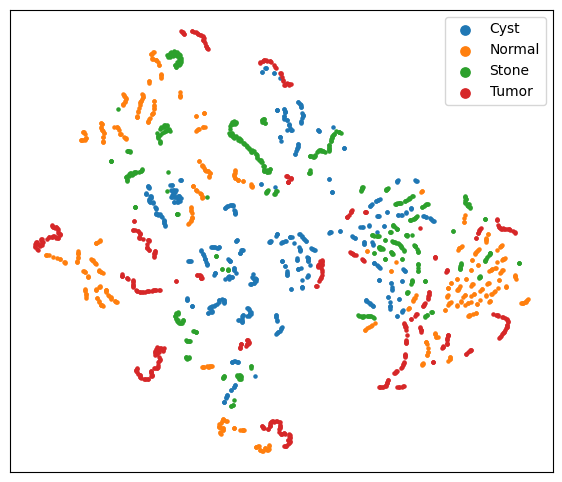

In [22]:
fig, ax = plt.subplots(figsize=(7, 6))
for c in classes: ax.scatter(*emb[(sub.label == c).values].T, s=5, label=c)
ax.legend(markerscale=3); ax.set_xticks([]); ax.set_yticks([])